In [211]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lu_factor, lu_solve

np.random.seed(42)

In [212]:

import matplotlib as mpl

# ---- STILE PAPER ----
mpl.rcParams.update({

    # Usa font LaTeX (coerente con paper)
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],

    # Dimensioni testo (standard journal)
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,

    # Spessori ottimizzati per stampa
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    # Tick dentro (stile PRL/JCP)
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Griglia molto leggera
    "grid.linestyle": ":",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,

    # Legenda minimale
    "legend.frameon": False,
})

Test Convergenza soluzione lineare

Time scale coeff:  250.0
dx:  0.01020408163265306
dt:  0.05
r:  0.4802000000000001
Slope (m): -5.1809964205198635e-11
Intercept (b): 0.9999999999971626
Expected Slope (m): 0.0
Slope (m): -0.6666666666673838
Intercept (b): 0.9999999999999034
Expected Slope (m): -0.6666666666666666
Slope (m): -1.4285714285716162
Intercept (b): 0.9999999999999175
Expected Slope (m): -1.4285714285714286
Slope (m): -1.666666666666739
Intercept (b): 0.9999999999999233
Expected Slope (m): -1.6666666666666667
Slope (m): -1.8181818181818317
Intercept (b): 0.9999999999999282
Expected Slope (m): -1.8181818181818181


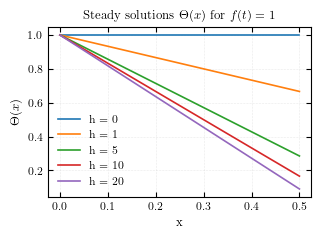

In [213]:
L = 0.5
Tf = 2500
nx = 50
nt = 50000

dx = L/(nx-1)
dt = Tf/nt

D = 0.001
r = D*dt/(dx**2)

print("Time scale coeff: ", L*L/D)
print("dx: ", dx)
print("dt: ", dt)
print("r: ", r)

plt.figure(figsize=(3.4, 2.2))

x_array = np.linspace(0, L, nx)
t_array = np.linspace(0,Tf,nt)

for h in [0,1,5,10,20]:

    A = np.zeros((nx, nx))
    B = np.zeros((nx, nx))

    # Nodi interni
    for i in range(1, nx-1):
        A[i, i-1] = -r/2
        A[i, i]   = 1 + r
        A[i, i+1] = -r/2

        B[i, i-1] = r/2
        B[i, i]   = 1 - r
        B[i, i+1] = r/2

    # Boundary sinistra (Dirichlet)
    A[0,0] = 1
    #B[0,0] = 1
    B[0,:] = 0
    
    # Boundary destra (Robin)
    A[-1, -3] = 1
    A[-1, -2] = -4
    A[-1, -1] = 3 + 2*h*dx

    B[-1, :] = 0

    lu, piv = lu_factor(A)

    T = np.zeros(shape=(nx,nt))

    # Initial condition
    T[:,0] = 0

    # Right boundary 
    f = 1
    T[0,0] = f

    for n in range(1,nt):
        b = B @ T[:,n-1]
        b[0] = f # impongo dirichlet
        T[:,n] = lu_solve((lu, piv), b)

    # Fit lineare
    m, b_fit = np.polyfit(x_array, T[:,-1], 1)

    print("Slope (m):", m)
    print("Intercept (b):", b_fit)
    print(f"Expected Slope (m): {-h/(1+h*L)}")

    plt.plot(x_array, m*x_array+b_fit, label=f"h = {h}")

plt.legend()
plt.title(r"Steady solutions $\Theta(x)$ for $f(t) = 1$")
plt.xlabel("x")
plt.ylabel(r"$\Theta(x)$")
plt.grid()

plt.savefig("assets/soluzione_lineare_nikolson.pdf")
plt.show()

Nikolson

In [214]:
def generate_random_f_from_white_noise(t_array: np.ndarray,sigma_white_noise: float=1, sigma_filter: float = 0.01, T_0: float = 0, oscillations_power: float = 1, verbose:bool=False) -> np.ndarray:
    
    if sigma_filter == 1:
        raise ValueError('sigma_filter can not be 0')
    
    nt = t_array.size
    if nt == 1:
        raise ValueError('nt must be greater than 1')

    dt = t_array[1]-t_array[0]

    # Genera white noise nel tempo
    # Proprietà da rispettare:
    # - Media nulla
    # - Matrice di correlazione proporzionale all'identità
    f = np.random.normal(0,sigma_white_noise,nt)

    f_hat = np.fft.rfft(f)
    freqs = np.fft.rfftfreq(nt, dt)

    # Applica filtro gaussiano nello spazio delle frequenze
    # NOTE: Il filtro gaussiano è una scelta di comodo, bisogna capire in base al problema
    # che tipo di filtro nello spazio delle frequenza applicare. Questo mi aspetto influenzi fortemente la fase 
    # di training e la risultante capacità di generalizzazione del modello.
    filter = np.exp(-(freqs**2)/(2*sigma_filter**2))

    f_hat_filtered = f_hat * filter

    f_filtered = np.fft.irfft(f_hat_filtered, n=nt)

    # Normalizza f_filtered e rendilo fisicamente coerente con una possibile oscillazione attorno a un valore noto.
    # Di default oscilla attorno a 0 con amplificazione unitaria
    f_filtered = (f_filtered - f_filtered.mean()) / f_filtered.std()
    f_filtered = T_0 + oscillations_power*f_filtered
    
    if verbose:
        plt.plot(t_array, f, label="White noise")
        plt.plot(t_array, f_filtered, label="f_filtered")
        plt.legend()
        plt.xlabel("Time")
        plt.ylabel("Temperature")
        plt.title("White noise e f risultante")
        plt.show()

    return f_filtered


Time scale coeff:  100.00000000000001
dx:  0.00101010101010101
dt:  0.1
r:  9.801000000000002


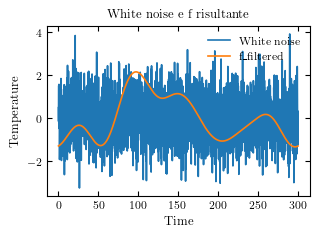

Text(0, 0.5, 'T')

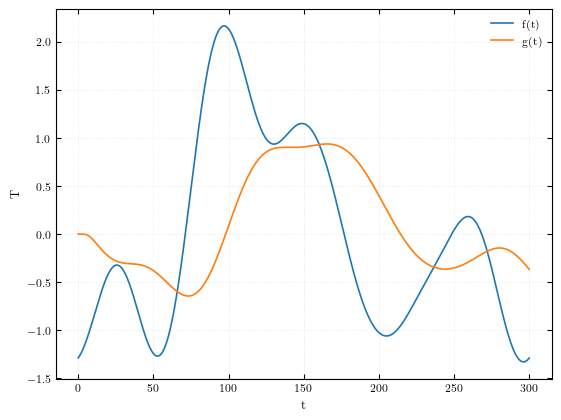

In [ ]:
L = 0.1
Tf = 300
nx = 100
nt = 3000

dx = L/(nx-1)
dt = Tf/nt

D = 0.0001
r = D*dt/(dx**2)

h = 1

print("Time scale coeff: ", L*L/D)
print("dx: ", dx)
print("dt: ", dt)
print("r: ", r)

plt.figure(figsize=(3.4, 2.2))

x_array = np.linspace(0, L, nx)
t_array = np.linspace(0,Tf,nt)

# Matrici A e B
A = np.zeros((nx, nx))
B = np.zeros((nx, nx))

# Nodi interni
for i in range(1, nx-1):
    A[i, i-1] = -r/2
    A[i, i]   = (1 + r)
    A[i, i+1] = -r/2

    B[i, i-1] = r/2
    B[i, i]   = (1 - r)
    B[i, i+1] = r/2

# Boundary sinistra (Dirichlet)
A[0,0] = 1
B[0,:] = 0

# Boundary destra (Robin)

A[-1, -3] = 1
A[-1, -2] = -4
A[-1, -1] = 3 + 2*h*dx
B[-1, :] = 0 

# Lu solver
lu, piv = lu_factor(A)

# Inizializzazione
T = np.zeros(shape=(nx,nt))

T[:,0] = 0 # Initial condition

f = generate_random_f_from_white_noise(t_array, sigma_filter=0.01, verbose=True) # random left boundary condition
T[0,0] = f[0]

# Time stepping
for n in range(1,nt):
    b = B @ T[:,n-1]
    b[0] = f[n] # impongo dirichlet
    T[:,n] = lu_solve((lu, piv), b)
    
    
plt.plot(t_array, T[0,:], label="f(t)")
plt.plot(t_array, T[-1,:], label="g(t)")
plt.legend()
plt.grid()
plt.xlabel("t")
plt.ylabel("T")